# MNIST: Layer-Wise SPSA vs. `torch.optim.SGD` (paper Sect. 4.2, Fig. 2)

**Implementation by**: Ananth Shyam, Rama Narasimha and Mahan Bhimireddy

**Paper**: B. Wulff, J. Schuecker, C. Bauckhage. *SPSA for Layer-Wise Training of Deep Networks.* ICANN 2018, LNCS 11141, pp. 564–573.

This notebook repeats the paper's MNIST experiment: a network with **771,270 parameters**, trained with forward passes only (layer-wise SPSA) and compared against a gradient baseline.

| | Paper (Sect. 4.2) | This notebook |
|---|---|---|
| Data | MNIST, one-hot labels $y_i \in \{0, 1\}^{10}$ | Same: 60,000 train / 10,000 test, pixels scaled to $[0, 1]$ |
| Network | "784×196×10, corresponding to a total number of 771,270 parameters" | **784×784×196×10 = 771,270 parameters.** This is the only topology with that count; 784×196×10 has 155,830. |
| Activation | tanh with $\beta = 1$ on all units | Same |
| SPSA | Bottom-up Algorithm 2, $a = 0.1$, $c = 0.1$, $t_{\max} = 50$, **weights first, then biases** of each layer; *"each application of SPSA entails $t_{max}$ partial weight updates, while GD only contains one update of all parameters per batch"* | Same algorithm, **applied per mini-batch** of 100 images, as that sentence implies. $c = 0.1$, $t_{\max} = 50$, gains $a_t = a/t$, $c_t = c/t^{1/6}$ restarted on every call. **$a = 0.01$** (see the step-size test below) |
| Holistic SPSA | "failed to learn the MNIST task" | Checked with a short run |
| Baseline | GD (`tf.train.GradientDescentOptimizer`), learning rate 0.01 | `torch.optim.SGD`, learning rate 0.01 (the paper's value), mini-batch 64 |
| Runs | "averaged over three successful runs" | 3 runs per method; all 3 are shown, and the paper-style average uses the successful ones |
| Epochs | Fig. 2: SPSA about 12, GD about 250 | SPSA 2 (each epoch = 600 mini-batches × 300 updates), SGD 30 |

**Objective.** The paper's TensorFlow optimiser minimises $E$ = the mean squared residual (`tf.reduce_mean`), so SPSA and SGD minimise that. The curves report $E$ per image, $\frac1n\sum_i \lVert y(x_i) - y_i\rVert^2$, which is the scale of the paper's Fig. 2a axis (1.2 to 2.7). The two differ only by a constant factor of 10.

**Not given by the paper,** so chosen by us:
- the initialisation: Glorot-uniform weights, zero biases (TensorFlow's default for dense layers);
- the batch sizes: 100 for SPSA, 64 for SGD;
- the success rule: a run is "successful" if it **learns**, meaning its final training error $E$ is below its starting value. The paper reports that without the weight/bias split it *"did not observe any learning behavior"*, but it does not define success.

The notebook runs on a CUDA GPU when one is available. The 3 runs of each method train **in parallel** as one batched model, each with its own shuffling.

### Why mini-batches and $a = 0.01$: a step-size test run before this notebook

The table below was measured before writing this notebook (1 run per setting, same initial network). The earlier full-dataset numbers come from the previous version of this notebook (3 runs, 12 epochs).

| SPSA variant | Result |
|---|---|
| Every SPSA evaluation on all 60,000 images, $a = 0.1$, 12 epochs | Test accuracy 47.7%; $E$ ends *above* its start (≈ 2.3 → 2.7) |
| Same, $a = 0.01$–$0.05$, 4 epochs | $E$ falls (2.34 → 1.6–1.9), but accuracy only reaches 19–31% |
| **Mini-batch 100**, $a = 0.1$ (the paper's value) | $E$ rises to ≈ 4.4; accuracy stuck near 43% |
| Mini-batch 100, $a = 0.02$ / $0.03$ | Peaks at 66–68% early on, then collapses to 15–26% within 1 epoch |
| **Mini-batch 100, $a = 0.01$** | Peaks at **72.8%** after ½ epoch with $E ≈ 1.1$, close to the paper's ≈ 72% and $E$ ≈ 1.3 |

- **What matters is how often SPSA updates.** Applying Algorithm 2 per mini-batch gives 180,000 updates per epoch instead of 300, and that is what makes SPSA learn quickly.
- **The paper's $a = 0.1$ is too large at this objective scale.** The paper's code is not available to check its exact scaling.
- **Watch for collapse.** $E \approx 1$ is also what a network gets if it outputs ≈ 0 for every digit. So a falling $E$ can hide a collapse in accuracy, and this notebook logs test accuracy throughout.

In [1]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
# scikit-learn is imported before torch on purpose: on some Windows set-ups, importing it
# after torch crashes the Python process without an error message (a DLL clash).
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
import torch

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 0
torch.manual_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print(f"PyTorch {torch.__version__} | device: {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))


def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def print_table(title, headers, rows):
    rows = [[str(v) for v in r] for r in rows]
    widths = [max(len(h), *(len(r[i]) for r in rows)) for i, h in enumerate(headers)]
    print(title)
    print(" | ".join(h.ljust(w) for h, w in zip(headers, widths)))
    print("-+-".join("-" * w for w in widths))
    for r in rows:
        print(" | ".join(v.ljust(w) for v, w in zip(r, widths)))
    print()

PyTorch 2.14.0+cu126 | device: cuda (NVIDIA GeForce RTX 3050 6GB Laptop GPU)


## 1. Data

The notebook reads `data/mnist/mnist.npz` at the repository root. If that file is missing, it downloads MNIST with `torchvision`.

train (60000, 784), test (10000, 784), class counts (train): [5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949]


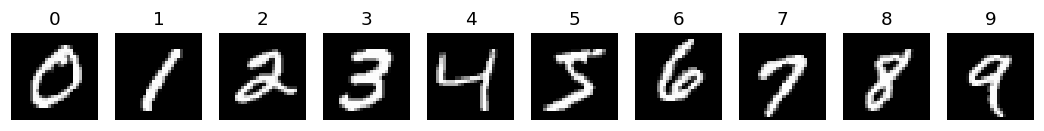

In [2]:
NPZ = os.path.join("..", "..", "data", "mnist", "mnist.npz")
if os.path.exists(NPZ):
    d = np.load(NPZ)
    xtr, ltr, xte, lte = d["train_images"], d["train_labels"], d["test_images"], d["test_labels"]
else:
    from torchvision.datasets import MNIST
    root = os.path.join("..", "..", "data", "mnist")
    tr, te = MNIST(root, train=True, download=True), MNIST(root, train=False, download=True)
    xtr, ltr, xte, lte = tr.data.numpy(), tr.targets.numpy(), te.data.numpy(), te.targets.numpy()

X_TR = torch.tensor(xtr.reshape(-1, 784) / 255.0, dtype=torch.float32, device=DEVICE)
X_TE = torch.tensor(xte.reshape(-1, 784) / 255.0, dtype=torch.float32, device=DEVICE)
L_TR = torch.tensor(ltr, dtype=torch.long, device=DEVICE)
L_TE = torch.tensor(lte, dtype=torch.long, device=DEVICE)
Y_TR = torch.nn.functional.one_hot(L_TR, 10).float()        # one-hot targets in {0, 1}^10
print(f"train {tuple(X_TR.shape)}, test {tuple(X_TE.shape)}, class counts (train): {torch.bincount(L_TR).tolist()}")

fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for k, ax in enumerate(axes):
    ax.imshow(xtr[np.where(ltr == k)[0][0]], cmap="gray"); ax.set_title(str(k)); ax.axis("off")
plt.show()

## 2. Network and objective

- There are 3 runs, trained in parallel: every weight has shape `(runs, out, in)` and every bias `(runs, 1, out)`.
- The forward pass goes through the 60,000 training images in chunks, so the six perturbed networks of one SPSA step (2 perturbations × 3 runs) fit in GPU memory.

In [3]:
SIZES, BETA, RUNS = [784, 784, 196, 10], 1.0, 3
N_PARAMS = sum(i * o + o for i, o in zip(SIZES[:-1], SIZES[1:]))
print(f"network {'x'.join(map(str, SIZES))}: {N_PARAMS:,} parameters")
assert N_PARAMS == 771_270


def init_params(runs, seed):
    """Glorot-uniform weights and zero biases (the TensorFlow default for dense layers)."""
    g = torch.Generator().manual_seed(seed)
    ps = []
    for n_in, n_out in zip(SIZES[:-1], SIZES[1:]):
        lim = (6.0 / (n_in + n_out)) ** 0.5
        ps.append(((torch.rand(runs, n_out, n_in, generator=g) * 2 - 1) * lim).to(DEVICE))
        ps.append(torch.zeros(runs, 1, n_out, device=DEVICE))
    return ps


def forward(x, ps):
    """x: (n, 784) or (B, n, 784); ps: [W1, b1, W2, b2, W3, b3] with a leading batch dim B -> (B, n, 10)."""
    a = x
    for l in range(len(ps) // 2):
        a = torch.tanh(BETA * (a @ ps[2 * l].transpose(1, 2) + ps[2 * l + 1]))
    return a


CHUNK = 10_000


@torch.no_grad()
def error_per_image(ps, x=X_TR, y=Y_TR):
    """E = (1/n) sum_i ||y(x_i) - y_i||^2, one value per network (the scale of Fig. 2a)."""
    total = 0.0
    for s in range(0, x.shape[0], CHUNK):
        total = total + ((forward(x[s:s + CHUNK], ps) - y[s:s + CHUNK]) ** 2).sum(dim=(1, 2))
    return total / x.shape[0]


def objective(ps):
    """What SPSA minimises: the mean squared residual (tf.reduce_mean), i.e. E / 10."""
    return error_per_image(ps) / 10.0


@torch.no_grad()
def predict(ps, x):
    out = torch.cat([forward(x[s:s + CHUNK], ps) for s in range(0, x.shape[0], CHUNK)], dim=1)
    return out.argmax(dim=2)                                  # (B, n)


def accuracy(ps, x, labels):
    return (predict(ps, x) == labels).float().mean(dim=1)    # (B,)

network 784x784x196x10: 771,270 parameters


## 3. Layer-wise SPSA per mini-batch (Sect. 4.2)

For **each mini-batch** of 100 images (each run draws its own), the layers are visited bottom-up ($l = 1, 2, 3$). Each layer gets **two separate calls of Algorithm 1**, first on the weights $W_l$ and then on the biases $b_l$ (the paper: *"Without this modification we did not observe any learning behavior"*). Each call runs:

$$\text{for } t = 1, \dots, 50: \quad a_t = \frac{a}{t}, \; c_t = \frac{0.1}{t^{1/6}}, \; \delta \sim \mathcal{U}\{-1, +1\}, \; \theta \leftarrow \theta - a_t\,\frac{E_B(\theta + c_t\delta) - E_B(\theta - c_t\delta)}{2c_t}\,\delta$$

Here $E_B$ is the mean squared residual on the mini-batch.

- **Cost:** 300 updates per mini-batch. One epoch is 600 mini-batches, which is 180,000 updates or 600 full-dataset passes.
- **Logging:** the mini-batch error is logged **after every update**. Every 50 mini-batches, the error on all 60,000 training images and the test accuracy are also logged.

`holistic=True` perturbs all 771,270 parameters in every step, with the same number of steps (the paper's holistic variant).

In [4]:
BATCH_SPSA, EVAL_EVERY = 100, 50


@torch.no_grad()
def train_spsa(epochs, a=0.01, c=0.1, t_max=50, holistic=False, max_batches=None, eval_every=EVAL_EVERY,
               seed=SEED, verbose=True):
    ps = init_params(RUNS, seed)
    gen = torch.Generator(device=DEVICE).manual_seed(seed + 1)
    n = X_TR.shape[0]
    n_batches = n // BATCH_SPSA
    total_batches = max_batches or epochs * n_batches
    n_layers = len(SIZES) - 1
    calls = [[i] for l in range(n_layers) for i in (2 * l, 2 * l + 1)]       # W1, b1, W2, b2, W3, b3
    if holistic:
        calls = [list(range(len(ps)))] * len(calls)
    upd_per_batch = len(calls) * t_max
    step_E = torch.empty(total_batches * upd_per_batch + 1, RUNS, device=DEVICE)
    hist = dict(eval_epoch=[0.0], eval_passes=[0.0], epoch_E=[error_per_image(ps).cpu()],
                epoch_test=[accuracy(ps, X_TE, L_TE).cpu()], epoch_train=[accuracy(ps, X_TR, L_TR).cpu()],
                epoch_time=[0.0])
    step_E[0] = hist["epoch_E"][0].to(DEVICE)
    k, t_start = 0, time.perf_counter()
    for b in range(total_batches):
        if b % n_batches == 0:
            perm = torch.argsort(torch.rand(RUNS, n, generator=gen, device=DEVICE), dim=1)
        idx = perm[:, (b % n_batches) * BATCH_SPSA:(b % n_batches + 1) * BATCH_SPSA]
        xb, yb = X_TR[idx], Y_TR[idx]                       # (RUNS, 100, 784), (RUNS, 100, 10)
        xb2, yb2 = torch.cat([xb, xb]), torch.cat([yb, yb])
        for group in calls:
            for t in range(1, t_max + 1):
                a_t, c_t = a / t, c / t ** (1.0 / 6.0)
                deltas = {i: torch.randint(0, 2, ps[i].shape, generator=gen, device=DEVICE).float() * 2 - 1 for i in group}
                both = [torch.cat([p + c_t * deltas[i], p - c_t * deltas[i]]) if i in deltas else torch.cat([p, p])
                        for i, p in enumerate(ps)]
                f = ((forward(xb2, both) - yb2) ** 2).mean(dim=(1, 2))        # E_B (tf.reduce_mean)
                diff = (f[:RUNS] - f[RUNS:]) / (2 * c_t)
                for i in group:
                    ps[i] = ps[i] - a_t * diff.view(-1, *[1] * (ps[i].dim() - 1)) * deltas[i]
                k += 1
                step_E[k] = ((forward(xb, ps) - yb) ** 2).sum(dim=2).mean(dim=1)   # batch E per image, after the update
        if (b + 1) % eval_every == 0 or b + 1 == total_batches:
            sync()
            hist["eval_epoch"].append((b + 1) / n_batches)
            hist["eval_passes"].append(2.0 * k * BATCH_SPSA / n)
            hist["epoch_E"].append(error_per_image(ps).cpu())
            hist["epoch_test"].append(accuracy(ps, X_TE, L_TE).cpu())
            hist["epoch_train"].append(accuracy(ps, X_TR, L_TR).cpu())
            hist["epoch_time"].append(time.perf_counter() - t_start)
            if verbose:
                print(f"epoch {(b + 1) / n_batches:5.2f} | E per run {np.round(hist['epoch_E'][-1].numpy(), 3)} | test acc "
                      f"{np.round(100 * hist['epoch_test'][-1].numpy(), 1)} % | {hist['epoch_time'][-1]:.0f} s", flush=True)
    for key in ("epoch_E", "epoch_test", "epoch_train"):
        hist[key] = torch.stack(hist[key]).numpy()
    for key in ("eval_epoch", "eval_passes", "epoch_time"):
        hist[key] = np.array(hist[key])
    hist["step_E"] = step_E[:k + 1].cpu().numpy()
    hist["updates_per_batch"] = upd_per_batch
    hist["updates_per_epoch"] = upd_per_batch * n_batches
    return ps, hist

### 3.1 Holistic SPSA check (paper: *"the holistic variant of SPSA failed to learn the MNIST task"*)

This runs 120 mini-batches (0.2 epochs, 36,000 updates) with the same settings, but every step perturbs all 771,270 parameters.

In [5]:
sync(); t0 = time.perf_counter()
ps_hol, hist_hol = train_spsa(epochs=1, holistic=True, max_batches=120, eval_every=20)
sync(); print(f"holistic SPSA: {time.perf_counter() - t0:.0f} s")

epoch  0.03 | E per run [3.237 3.417 3.297] | test acc [43.8 46.2 39.9] % | 26 s


epoch  0.07 | E per run [3.6   3.384 3.365] | test acc [50.6 56.7 52.2] % | 53 s


epoch  0.10 | E per run [3.628 3.638 3.518] | test acc [56.4 60.9 56.3] % | 79 s


epoch  0.13 | E per run [3.524 3.634 3.546] | test acc [61.9 58.2 56. ] % | 106 s


epoch  0.17 | E per run [3.613 3.506 3.614] | test acc [61.3 61.5 56.8] % | 134 s


epoch  0.20 | E per run [3.449 3.502 3.605] | test acc [63.1 60.  57.1] % | 161 s


holistic SPSA: 162 s


### 3.2 Layer-wise SPSA: 3 runs × 2 epochs (360,000 updates per run)

In [6]:
SPSA_EPOCHS = 2
sync(); t0 = time.perf_counter()
ps_spsa, hist_spsa = train_spsa(epochs=SPSA_EPOCHS)
sync(); TIME_SPSA = time.perf_counter() - t0
print(f"layer-wise SPSA: {TIME_SPSA:.0f} s for {RUNS} runs in parallel")

epoch  0.08 | E per run [1.423 1.318 1.377] | test acc [53.3 57.5 51.1] % | 38 s


epoch  0.17 | E per run [1.315 1.23  1.296] | test acc [66.3 69.1 62.1] % | 74 s


epoch  0.25 | E per run [1.275 1.232 1.267] | test acc [69.5 71.9 67. ] % | 108 s


epoch  0.33 | E per run [1.222 1.2   1.253] | test acc [73.2 73.5 69.1] % | 144 s


epoch  0.42 | E per run [1.173 1.146 1.228] | test acc [72.2 72.7 73.2] % | 178 s


epoch  0.50 | E per run [1.163 1.11  1.224] | test acc [73.2 73.4 70. ] % | 211 s


... (15 outputs left out)

epoch  1.83 | E per run [1.347 1.297 1.179] | test acc [29.9 31.6 41.4] % | 754 s


epoch  1.92 | E per run [1.104 1.259 1.313] | test acc [29.4 30.3 35.1] % | 788 s


epoch  2.00 | E per run [1.239 1.141 1.231] | test acc [26.7 36.8 37.5] % | 822 s


layer-wise SPSA: 822 s for 3 runs in parallel


## 4. Baseline: `torch.optim.SGD`, learning rate 0.01

- **Settings:** the paper's learning rate of 0.01, mini-batches of 64, the same objective (mean squared residual), and the same initial networks as the SPSA runs (the same seed).
- **Shuffling:** every run reshuffles the data each epoch.
- **Logging:** $E$ and test accuracy are logged after every epoch, and the full training error is also logged every 50 steps for the loss-vs-evaluations plot.
- **Cost:** one step (forward + backward on 64 images) counts as $3 \times 64 / 60000$ full passes.

In [7]:
def train_sgd(epochs, lr=0.01, batch=64, seed=SEED, log_every=50):
    ps = [p.clone().requires_grad_(True) for p in init_params(RUNS, seed)]
    opt = torch.optim.SGD(ps, lr=lr)
    gen = torch.Generator(device=DEVICE).manual_seed(seed + 2)
    n = X_TR.shape[0]
    hist = dict(step_E=[error_per_image(ps).cpu()], step_passes=[0.0], epoch_E=[error_per_image(ps).cpu()],
                epoch_test=[accuracy(ps, X_TE, L_TE).cpu()], epoch_train=[accuracy(ps, X_TR, L_TR).cpu()],
                epoch_time=[0.0])
    passes, step, t_start = 0.0, 0, time.perf_counter()
    for epoch in range(1, epochs + 1):
        perm = torch.argsort(torch.rand(RUNS, n, generator=gen, device=DEVICE), dim=1)
        for s in range(0, n, batch):
            idx = perm[:, s:s + batch]                                  # each run its own mini-batch
            opt.zero_grad()
            loss = ((forward(X_TR[idx], ps) - Y_TR[idx]) ** 2).mean(dim=(1, 2)).sum()   # mean per run
            loss.backward()
            opt.step()
            passes += 3.0 * idx.shape[1] / n
            step += 1
            if step % log_every == 0:
                hist["step_E"].append(error_per_image(ps).cpu()); hist["step_passes"].append(passes)
        sync()
        hist["epoch_E"].append(error_per_image(ps).cpu())
        hist["epoch_test"].append(accuracy(ps, X_TE, L_TE).cpu())
        hist["epoch_train"].append(accuracy(ps, X_TR, L_TR).cpu())
        hist["epoch_time"].append(time.perf_counter() - t_start)
        if epoch % 5 == 0 or epoch == 1:
            print(f"epoch {epoch:2d} | E per run {np.round(hist['epoch_E'][-1].numpy(), 3)} | test acc "
                  f"{np.round(100 * hist['epoch_test'][-1].numpy(), 1)} % | {hist['epoch_time'][-1]:.0f} s", flush=True)
    for k in ("step_E", "epoch_E", "epoch_test", "epoch_train"):
        hist[k] = torch.stack(hist[k]).numpy()
    hist["step_passes"] = np.array(hist["step_passes"])
    hist["eval_epoch"] = np.arange(epochs + 1, dtype=float)
    hist["eval_passes"] = 3.0 * hist["eval_epoch"]
    hist["epoch_time"] = np.array(hist["epoch_time"])
    return [p.detach() for p in ps], hist


SGD_EPOCHS = 30
SGD_TABLE_EPOCHS = (0, 1, 2, 5, 10, 15, 20, 25, 30)
sync(); t0 = time.perf_counter()
ps_sgd, hist_sgd = train_sgd(epochs=SGD_EPOCHS)
sync(); TIME_SGD = time.perf_counter() - t0
print(f"SGD: {TIME_SGD:.0f} s for {RUNS} runs in parallel")

epoch  1 | E per run [0.557 0.553 0.558] | test acc [80.6 80.3 80.4] % | 5 s


epoch  5 | E per run [0.405 0.406 0.41 ] | test acc [87.4 87.4 87.5] % | 27 s


epoch 10 | E per run [0.336 0.337 0.342] | test acc [90.  89.8 90. ] % | 54 s


epoch 15 | E per run [0.294 0.294 0.3  ] | test acc [91.4 91.1 91.4] % | 81 s


epoch 20 | E per run [0.266 0.266 0.271] | test acc [92.3 92.1 92.1] % | 108 s


epoch 25 | E per run [0.246 0.247 0.251] | test acc [93.  92.6 92.8] % | 135 s


epoch 30 | E per run [0.232 0.231 0.237] | test acc [93.3 93.2 93.1] % | 162 s


SGD: 167 s for 3 runs in parallel


## 5. Results

### 5.1 Per-run results and the paper-style average

A run is called **successful** if it learns: its final training error $E$ is below its starting value. The paper averages its curves over three successful runs, without defining success.

In [8]:
learned = lambda h: h["epoch_E"][-1] < h["epoch_E"][0]       # final training error below the starting value
ok_spsa, ok_sgd = learned(hist_spsa), learned(hist_sgd)


def metrics(ps):
    pred = predict(ps, X_TE).cpu().numpy()
    true = L_TE.cpu().numpy()
    out = []
    for p in pred:
        pr, rc, f1, _ = precision_recall_fscore_support(true, p, average="macro", zero_division=0)
        out.append((100 * (p == true).mean(), 100 * pr, 100 * rc, 100 * f1))
    return np.array(out), pred


M_SPSA, PRED_SPSA = metrics(ps_spsa)
M_SGD, PRED_SGD = metrics(ps_sgd)
M_HOL, _ = metrics(ps_hol)

rows = []
for name, h, M, ok in (("Holistic SPSA", hist_hol, M_HOL, learned(hist_hol)),
                       ("Layer-wise SPSA", hist_spsa, M_SPSA, ok_spsa),
                       ("SGD (torch.optim.SGD)", hist_sgd, M_SGD, ok_sgd)):
    for r in range(RUNS):
        kb = int(h["epoch_test"][:, r].argmax())
        rows.append((name, r, f"{h['eval_epoch'][-1]:.2f}", f"{h['eval_passes'][-1]:,.0f}", f"{h['epoch_E'][0][r]:.3f}",
                     f"{h['epoch_E'][-1][r]:.3f}", f"{100 * h['epoch_test'][kb, r]:.1f} @ {h['eval_epoch'][kb]:.2f}",
                     f"{100 * h['epoch_train'][-1][r]:.1f}", *(f"{v:.1f}" for v in M[r]), "yes" if ok[r] else "no"))
print_table("Per-run results at the end of training (test metrics on the 10,000 test images; precision/recall/F1 = macro, %)",
            ["method", "run", "epochs", "full passes", "E start", "E end", "best test acc @ epoch", "train acc",
             "test acc", "precision", "recall", "F1", "successful"], rows)

for name, h, ok in (("Layer-wise SPSA", hist_spsa, ok_spsa), ("SGD", hist_sgd, ok_sgd)):
    print(f"{name}: {ok.sum()} of {RUNS} runs successful")
avg = lambda h, ok, k: h[k][:, ok].mean(axis=1) if ok.any() else h[k].mean(axis=1)
print()
print_table("Layer-wise SPSA, paper-style average over successful runs (E per image on all 60,000 training images)",
            ["epoch", "full passes", "E", "train acc %", "test acc %"],
            [(f"{e:.2f}", f"{p:,.0f}", f"{E:.3f}", f"{100 * tr:.1f}", f"{100 * te:.1f}") for e, p, E, tr, te in
             zip(hist_spsa["eval_epoch"], hist_spsa["eval_passes"], avg(hist_spsa, ok_spsa, "epoch_E"),
                 avg(hist_spsa, ok_spsa, "epoch_train"), avg(hist_spsa, ok_spsa, "epoch_test"))])
print_table("SGD, average over successful runs", ["epoch", "full passes", "E", "test acc %"],
            [(e, f"{3 * e}", f"{avg(hist_sgd, ok_sgd, 'epoch_E')[e]:.3f}", f"{100 * avg(hist_sgd, ok_sgd, 'epoch_test')[e]:.1f}")
             for e in SGD_TABLE_EPOCHS])
print(f"Wall-clock: SPSA {TIME_SPSA:.0f} s ({SPSA_EPOCHS} epochs), SGD {TIME_SGD:.0f} s ({SGD_EPOCHS} epochs), "
      f"3 runs in parallel each")

Per-run results at the end of training (test metrics on the 10,000 test images; precision/recall/F1 = macro, %)
method                | run | epochs | full passes | E start | E end | best test acc @ epoch | train acc | test acc | precision | recall | F1   | successful
----------------------+-----+--------+-------------+---------+-------+-----------------------+-----------+----------+-----------+--------+------+-----------
Holistic SPSA         | 0   | 0.20   | 120         | 2.436   | 3.449 | 63.1 @ 0.20           | 61.7      | 63.1     | 63.9      | 62.4   | 61.7 | no        
Holistic SPSA         | 1   | 0.20   | 120         | 2.132   | 3.502 | 61.5 @ 0.17           | 59.4      | 60.0     | 61.3      | 59.1   | 57.2 | no        
Holistic SPSA         | 2   | 0.20   | 120         | 2.395   | 3.605 | 57.1 @ 0.20           | 56.1      | 57.1     | 56.7      | 56.6   | 55.8 | no        
Layer-wise SPSA       | 0   | 2.00   | 1,200       | 2.436   | 1.239 | 73.2 @ 0.33           | 27.8    

### 5.2 Fig. 2 style: training error and test accuracy vs. epoch

Thick lines are the averages over the successful runs, as in the paper; thin lines are the individual runs. SPSA is evaluated every 50 mini-batches (1/12 of an epoch).

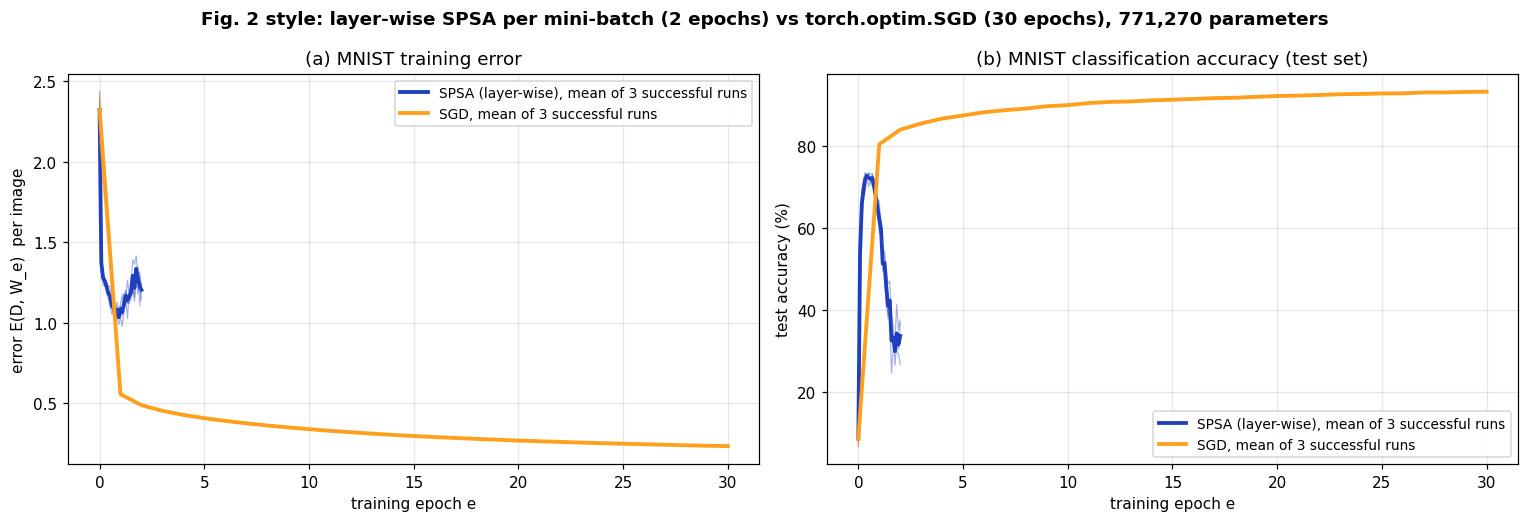

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for h, ok, color, name in ((hist_spsa, ok_spsa, "#1f3fbf", "SPSA (layer-wise)"), (hist_sgd, ok_sgd, "#ff9f1c", "SGD")):
    ep = h["eval_epoch"]
    for r in range(RUNS):
        axes[0].plot(ep, h["epoch_E"][:, r], color=color, lw=0.8, alpha=0.4)
        axes[1].plot(ep, 100 * h["epoch_test"][:, r], color=color, lw=0.8, alpha=0.4)
    axes[0].plot(ep, avg(h, ok, "epoch_E"), color=color, lw=2.5, label=f"{name}, mean of {ok.sum()} successful runs")
    axes[1].plot(ep, 100 * avg(h, ok, "epoch_test"), color=color, lw=2.5, label=f"{name}, mean of {ok.sum()} successful runs")
axes[0].set(xlabel="training epoch e", ylabel="error E(D, W_e)  per image", title="(a) MNIST training error")
axes[1].set(xlabel="training epoch e", ylabel="test accuracy (%)", title="(b) MNIST classification accuracy (test set)")
for ax in axes:
    ax.legend(fontsize=9)
fig.suptitle("Fig. 2 style: layer-wise SPSA per mini-batch (2 epochs) vs torch.optim.SGD (30 epochs), 771,270 parameters", fontweight="bold")
plt.tight_layout()
plt.show()

### 5.3 Loss vs. computational cost

**Per update (left):** SPSA's mini-batch error is logged after every one of its 360,000 updates, shown here as a moving average over 3,000 updates (10 mini-batches).

**Per full pass over the training set (right):** compute measured the same way for both methods (SPSA: 2 passes per update; SGD: forward + backward ≈ 3 × the mini-batch fraction).

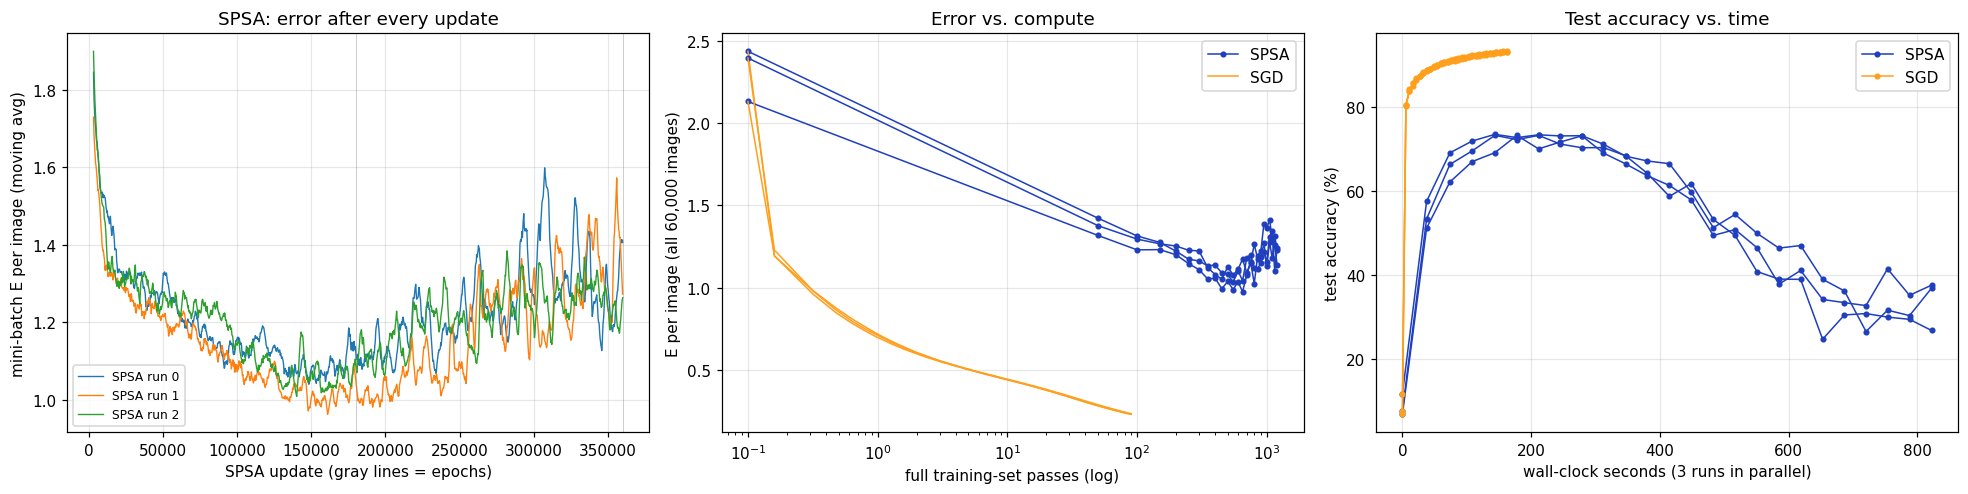

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
W = min(3000, len(hist_spsa["step_E"]) // 2)
for r in range(RUNS):
    sm = np.convolve(hist_spsa["step_E"][:, r], np.ones(W) / W, mode="valid")
    axes[0].plot(np.arange(len(sm)) + W, sm, lw=0.9, label=f"SPSA run {r}")
for k in range(1, SPSA_EPOCHS + 1):
    axes[0].axvline(k * hist_spsa["updates_per_epoch"], color="gray", lw=0.5, alpha=0.5)
axes[0].set(xlabel="SPSA update (gray lines = epochs)", ylabel="mini-batch E per image (moving avg)",
            title="SPSA: error after every update")
axes[0].legend(fontsize=8)
for r in range(RUNS):
    axes[1].plot(np.maximum(hist_spsa["eval_passes"], 1e-1), hist_spsa["epoch_E"][:, r], color="#1f3fbf", marker="o",
                 ms=3, lw=1, label="SPSA" if r == 0 else None)
    axes[1].plot(np.maximum(hist_sgd["step_passes"], 1e-1), hist_sgd["step_E"][:, r], color="#ff9f1c", lw=1,
                 label="SGD" if r == 0 else None)
axes[1].set(xscale="log", xlabel="full training-set passes (log)", ylabel="E per image (all 60,000 images)", title="Error vs. compute")
axes[1].legend()
for h, color, name in ((hist_spsa, "#1f3fbf", "SPSA"), (hist_sgd, "#ff9f1c", "SGD")):
    for r in range(RUNS):
        axes[2].plot(h["epoch_time"], 100 * h["epoch_test"][:, r], color=color, marker="o", ms=3, lw=1,
                     label=name if r == 0 else None)
axes[2].set(xlabel="wall-clock seconds (3 runs in parallel)", ylabel="test accuracy (%)", title="Test accuracy vs. time")
axes[2].legend()
plt.tight_layout()
plt.show()

### 5.4 Confusion matrices and per-class results (best run of each method)

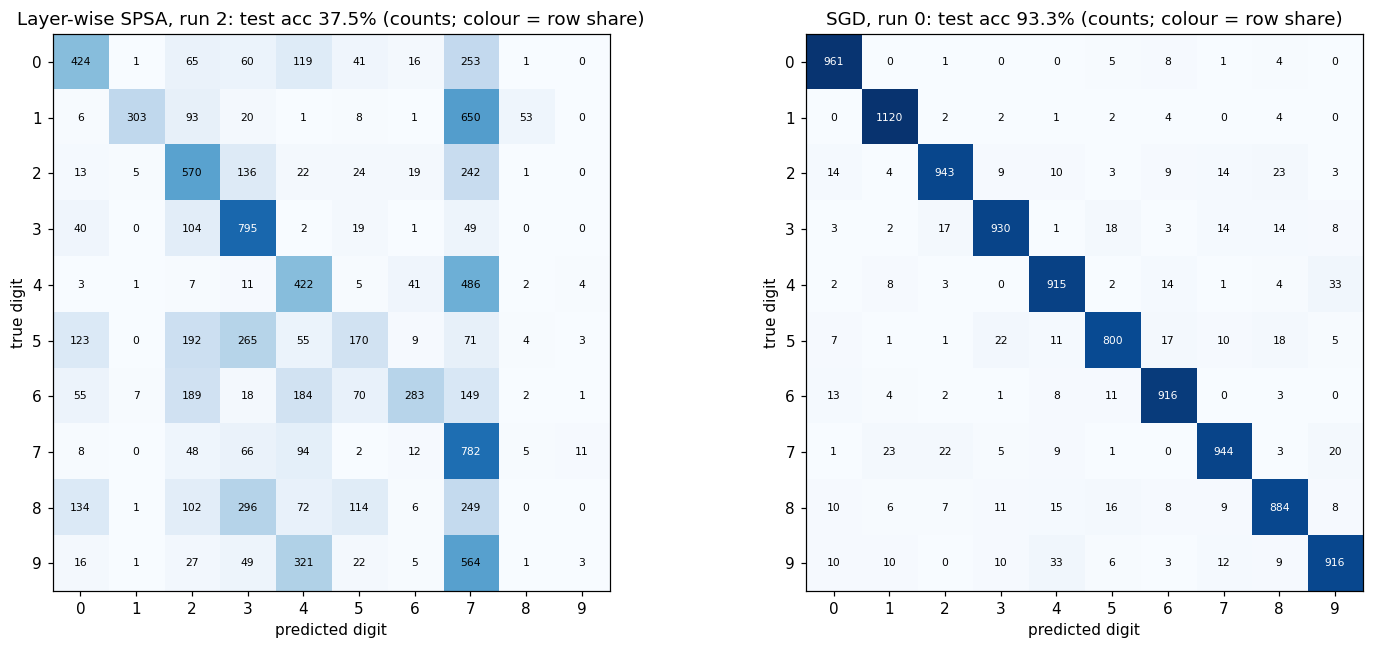

Per-class test metrics, best run of each method (%)
digit | count | SPSA precision | SPSA recall | SPSA F1 | SGD precision | SGD recall | SGD F1
------+-------+----------------+-------------+---------+---------------+------------+-------
0     | 980   | 51.6           | 43.3        | 47.1    | 94.1          | 98.1       | 96.1  
1     | 1135  | 95.0           | 26.7        | 41.7    | 95.1          | 98.7       | 96.8  
2     | 1032  | 40.8           | 55.2        | 46.9    | 94.5          | 91.4       | 92.9  
3     | 1010  | 46.3           | 78.7        | 58.3    | 93.9          | 92.1       | 93.0  
4     | 982   | 32.7           | 43.0        | 37.1    | 91.2          | 93.2       | 92.2  
5     | 892   | 35.8           | 19.1        | 24.9    | 92.6          | 89.7       | 91.1  
6     | 958   | 72.0           | 29.5        | 41.9    | 93.3          | 95.6       | 94.4  
7     | 1028  | 22.4           | 76.1        | 34.6    | 93.9          | 91.8       | 92.9  
8     | 974   | 0.

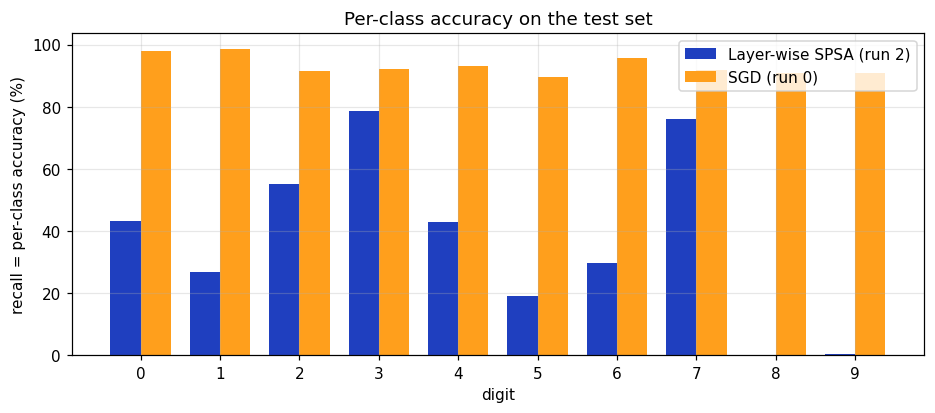

In [11]:
best_spsa, best_sgd = int(M_SPSA[:, 0].argmax()), int(M_SGD[:, 0].argmax())
true = L_TE.cpu().numpy()
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, pred, name, r in ((axes[0], PRED_SPSA, "Layer-wise SPSA", best_spsa), (axes[1], PRED_SGD, "SGD", best_sgd)):
    cm = confusion_matrix(true, pred[r], labels=range(10))
    cmn = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cmn[i, j] > 0.6 else "black")
    ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.grid(False)
    ax.set(xlabel="predicted digit", ylabel="true digit",
           title=f"{name}, run {r}: test acc {100 * (pred[r] == true).mean():.1f}% (counts; colour = row share)")
plt.tight_layout()
plt.show()

pr_s, rc_s, f1_s, sup = precision_recall_fscore_support(true, PRED_SPSA[best_spsa], labels=range(10), zero_division=0)
pr_g, rc_g, f1_g, _ = precision_recall_fscore_support(true, PRED_SGD[best_sgd], labels=range(10), zero_division=0)
print_table("Per-class test metrics, best run of each method (%)",
            ["digit", "count", "SPSA precision", "SPSA recall", "SPSA F1", "SGD precision", "SGD recall", "SGD F1"],
            [(k, sup[k], f"{100 * pr_s[k]:.1f}", f"{100 * rc_s[k]:.1f}", f"{100 * f1_s[k]:.1f}",
              f"{100 * pr_g[k]:.1f}", f"{100 * rc_g[k]:.1f}", f"{100 * f1_g[k]:.1f}") for k in range(10)])

fig, ax = plt.subplots(figsize=(10, 3.8))
w = 0.38
ax.bar(np.arange(10) - w / 2, 100 * rc_s, w, label=f"Layer-wise SPSA (run {best_spsa})", color="#1f3fbf")
ax.bar(np.arange(10) + w / 2, 100 * rc_g, w, label=f"SGD (run {best_sgd})", color="#ff9f1c")
ax.set(xticks=range(10), xlabel="digit", ylabel="recall = per-class accuracy (%)", title="Per-class accuracy on the test set")
ax.legend()
plt.show()

### 5.5 Example predictions

The first row shows test digits that SPSA gets wrong and SGD gets right. The second shows random test digits with both methods' predictions (best run of each).

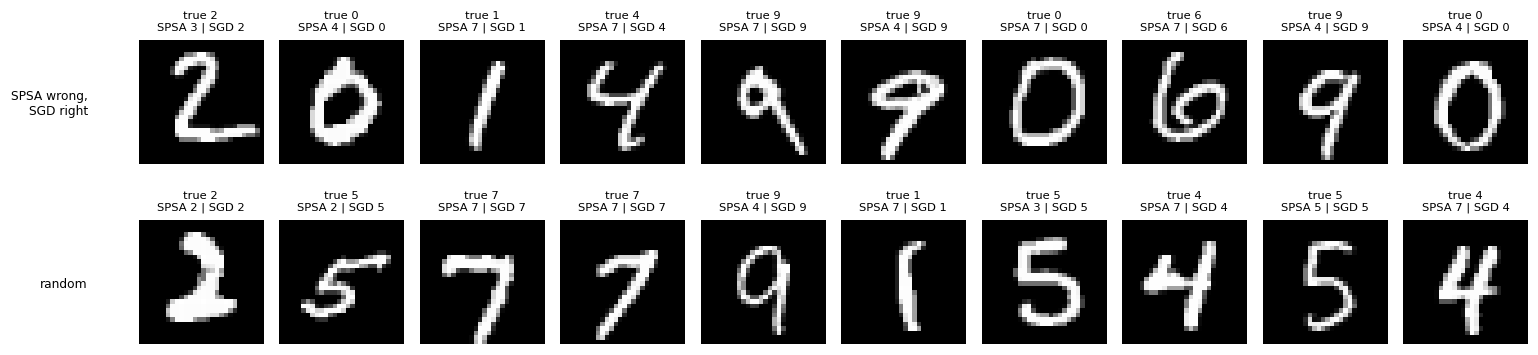

In [12]:
ps_wrong = np.where((PRED_SPSA[best_spsa] != true) & (PRED_SGD[best_sgd] == true))[0][:10]
rand = np.random.default_rng(0).choice(len(true), 10, replace=False)
fig, axes = plt.subplots(2, 10, figsize=(14, 3.6))
for row, idx in enumerate((ps_wrong, rand)):
    for k, ax in enumerate(axes[row]):
        ax.axis("off")
        if k < len(idx):
            i = idx[k]
            ax.imshow(xte[i], cmap="gray")
            ax.set_title(f"true {true[i]}\nSPSA {PRED_SPSA[best_spsa][i]} | SGD {PRED_SGD[best_sgd][i]}", fontsize=7.5)
axes[0, 0].text(-12, 14, "SPSA wrong,\nSGD right", fontsize=8, ha="right", va="center")
axes[1, 0].text(-12, 14, "random", fontsize=8, ha="right", va="center")
plt.tight_layout()
plt.show()

In [13]:
# Numbers used in the takeaways below, printed from this run
print("holistic SPSA, test acc per run after 0.2 epochs:", np.round(M_HOL[:, 0], 1), "| E:", np.round(hist_hol["epoch_E"][-1], 3))
print("layer-wise SPSA, test acc per run:", np.round(M_SPSA[:, 0], 1), "| E:", np.round(hist_spsa["epoch_E"][-1], 3),
      "| successful:", ok_spsa)
print("layer-wise SPSA, mean test acc (successful runs) at", np.round(hist_spsa["eval_epoch"], 2), ":", np.round(100 * avg(hist_spsa, ok_spsa, "epoch_test"), 1))
print("layer-wise SPSA, best test acc per run:", np.round(100 * hist_spsa["epoch_test"].max(axis=0), 1), "at epochs",
      hist_spsa["eval_epoch"][hist_spsa["epoch_test"].argmax(axis=0)])
print("SGD, test acc per run:", np.round(M_SGD[:, 0], 1), "| E:", np.round(hist_sgd["epoch_E"][-1], 3))
print("SGD, mean test acc per epoch:", np.round(100 * avg(hist_sgd, ok_sgd, "epoch_test"), 1))
print(f"full passes: SPSA {hist_spsa['eval_passes'][-1]:,.0f}, SGD {SGD_EPOCHS * 3}")

holistic SPSA, test acc per run after 0.2 epochs: [63.1 60.  57.1] | E: [3.449 3.502 3.605]
layer-wise SPSA, test acc per run: [26.7 36.8 37.5] | E: [1.239 1.141 1.231] | successful: [ True  True  True]
layer-wise SPSA, mean test acc (successful runs) at [0.   0.08 0.17 0.25 0.33 0.42 0.5  0.58 0.67 0.75 0.83 0.92 1.   1.08
 1.17 1.25 1.33 1.42 1.5  1.58 1.67 1.75 1.83 1.92 2.  ] : [ 8.6 54.  65.8 69.5 72.  72.7 72.2 72.  72.2 70.2 67.7 65.  62.2 59.7
 51.3 51.5 45.7 41.  42.3 32.6 33.3 30.  34.3 31.6 33.7]
layer-wise SPSA, best test acc per run: [73.2 73.5 73.2] at epochs [0.33333333 0.33333333 0.41666667]
SGD, test acc per run: [93.3 93.2 93.1] | E: [0.232 0.231 0.237]
SGD, mean test acc per epoch: [ 8.6 80.4 83.9 85.5 86.7 87.4 88.2 88.7 89.1 89.7 89.9 90.4 90.7 90.8
 91.1 91.3 91.4 91.6 91.8 92.  92.2 92.3 92.4 92.6 92.7 92.8 92.8 93.
 93.  93.2 93.2]
full passes: SPSA 1,200, SGD 90


## 6. Takeaways

All numbers come from the run above: 3 runs per method, 771,270 parameters, on the GPU.

### What matches the paper
- **Layer-wise SPSA reaches the paper's level.** With SPSA applied per mini-batch, the mean test accuracy of the 3 runs reaches **72.7%** after 0.42 epochs (73.2%, 73.5% and 73.2% per run at their best), with training error **$E \approx 1.18$**. The paper's Fig. 2 shows ≈ 72% and $E \approx 1.3$.
  - It gets there quickly: 54% after 50 mini-batches and 66% after 100.
  - All 3 runs learn ($E$: 2.13–2.44 → 1.14–1.24), consistent with the paper's *"In most of the runs, SPSA training was successful."*
- **This is training without backpropagation** on a network of close to a million parameters, which is the paper's goal: *"to show that SPSA training is feasible even for a total number of parameters close to a million."*
- **Holistic SPSA fails in the paper's sense.** Its training error **rises** in all 3 runs (2.13–2.44 → 3.45–3.61), whereas layer-wise SPSA's error falls. Note, though, that its test accuracy still reaches 57–63% in 0.2 epochs, so it is not doing nothing. The paper's *"failed to learn"* is judged on the error.

### What does not match, and why
- **Accuracy collapses after the peak.** After about half an epoch, the layer-wise runs lose accuracy steadily: 62% after 1 epoch and **34% after 2 epochs**. Meanwhile $E$ stays near 1.1–1.3.
  - $E \approx 1$ is also what a network gets by outputting ≈ 0 for every digit. So the squared error can stay low while the network drifts towards that trivial output, and the argmax becomes unreliable.
  - The per-class table, measured at the end (after the collapse), shows this: digits 8 and 9 are almost never predicted.
  - The paper plots SPSA only up to ≈ 12 of its epochs and does not show a collapse. Its epochs may hold far fewer updates than ours (it does not give its batch size), so its run may simply have stopped before this point.
- **We use $a = 0.01$, not the paper's 0.1.** At our objective scale (mean squared residual on a batch of 100), $a = 0.1$ makes the error rise (≈ 4.4 in the step-size test). The paper's batch size and exact objective scale are not reported, and both change the effective step size.
- **The mini-batch application is our reading of the paper.** The paper says SPSA entails $t_{max}$ updates *"while GD only contains one update of all parameters per batch."* Evaluating SPSA on the full training set instead gives only 47.7% after 12 epochs (previous version of this notebook).

### SPSA vs. SGD
- **SGD is far ahead.** `torch.optim.SGD` with the paper's learning rate of 0.01 (batch 64) reaches **80.4%** after 1 epoch and **93.2%** after 30, with the same result in all 3 runs ($E$ = 0.23) and no collapse.
- **It also uses far less compute.** It reaches SPSA's peak accuracy within its first epoch (3 full passes), while SPSA needs ≈ 250 passes to get there. Its whole 30 epochs take 90 passes and 167 s, against SPSA's 1,200 passes and 822 s.
- **The paper's own gradient baseline was much slower** (≈ 40% at epoch 12, ≈ 75% after ≈ 250 epochs). The paper also says: *"we neither aim for a quantitative comparison between the two approaches nor for achieving state of the art results (<1% error rate)."*

### In one line
Applied per mini-batch, layer-wise SPSA reproduces the paper's MNIST result: ≈ 73% test accuracy and $E \approx 1.2$, without backpropagation. Holistic SPSA's error rises instead. Beyond the paper's plotted range, accuracy collapses, while SGD reaches 93% at a fraction of the cost.